# AP 155 Lab Exercise
---
## Exercise 8: Minimization

_Instructions_: 
- **Report figure:** A 2 by 2 figure plot. Upper row contains the plot of the actual functions. Lower row contains a plot of their derivatives. Use markers to plot the found local extrema by the golden section search algorithm.  
- **Report discussion:** What happens if a number other than the golden ratio is used to perform the *golden* section search algorithm?
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: de Vera, Clarence Joseph
- _Student No._: 2024-11757
- _Section_: THR-TX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view?usp=sharing) (Note: percentages may still be tweaked)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_:_

---
## Section 1: Report

### Report figure

<img src="figures/cat.jpg" alt="Alt text" width=45%> <img src="figures/cat.jpg" alt="Alt text" width=45%>


EDIT ME. See instruction above for what to include. Insert caption here, a short description what the figure illustrates. The syntax in markdown for putting a figure is `![Description](local_file_name.png)` or `<img src="/path/to_image.jpg" alt="Alt text" width=45%>`. Make sure the figure has complete elements.


### Report discussion
**What happens if a number other than the golden ratio is used to perform the *golden* section search algorithm?**

If a number other than the golden ratio is used, the algorithm will still narrow down the bracket and converge, but its efficiency is sacrificed. The golden ratio is chosen specifically because its geometry allows the nested intervals to overlap perfectly. This stores and reuses one of the evaluation points from the previous step in the next iteration, leading to only one new function evaluation per loop. If we use a different ratio, the points won't align, forcing the code to evaluate the function at two new points during every single step instead of just one. This doubles the iterations required to achieve the same precision.

### Other comments
- EDIT ME
- A self reflection can be placed here.
- This portion is not graded.
- You may insert further questions here.


---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math

### Problem 1: Minimization

Consider the following equations:

Eq. 5.91
$$
\phi(x) = x^4 - 9x^3 + 25x^2 - 24x + 4
$$

Eq. 5.145
$$
f(x) = -x^5 + 4x^4 - 4x^3 + x^2 e^x - 2x^2 - 4xe^x + 8x + 4e^x - 8
$$


1. Plot each of the functions. Get a rough estimate of the local minima and maxima
2. Implement 5.5.2.2 (golden section search), then determine the local minima and maxima of Eq. 5.91 and Eq. 5.145.
3. Report figure: A 2 by 2 figure plot. Upper row contains the plot of the actual functions. Lower row contains a plot of their derivatives. Use markers to plot the found local extrema by the golden section search algorithm. 

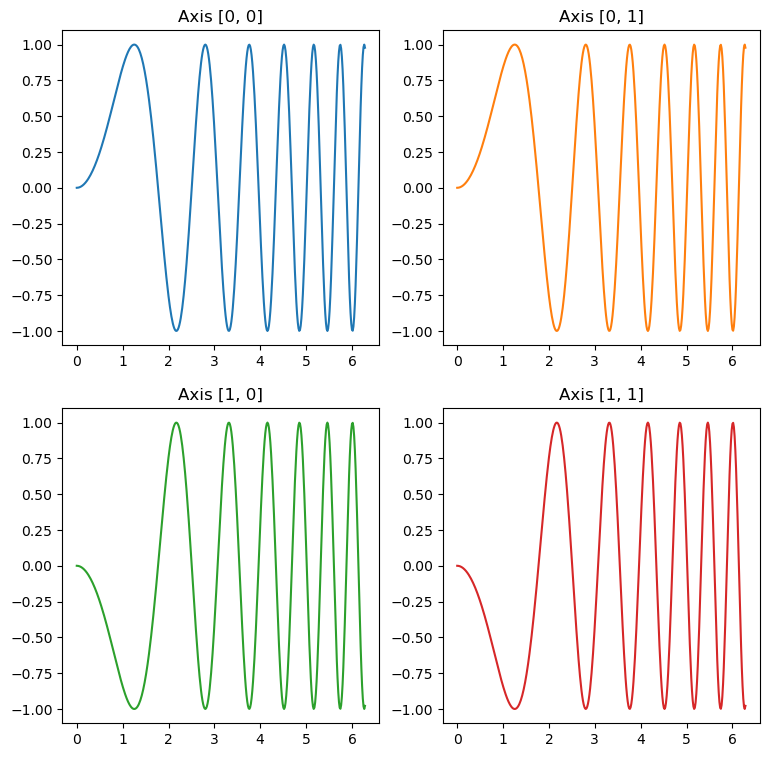

In [2]:
#sample incomplete 2 by 2 plot 

x = np.linspace(0, 2 * np.pi, 400)
y = np.sin(x ** 2)

fig, axs = plt.subplots(2, 2, figsize = (9,9))
axs[0, 0].plot(x, y)
axs[0, 0].set_title('Axis [0, 0]')
axs[0, 1].plot(x, y, 'tab:orange')
axs[0, 1].set_title('Axis [0, 1]')
axs[1, 0].plot(x, -y, 'tab:green')
axs[1, 0].set_title('Axis [1, 0]')
axs[1, 1].plot(x, -y, 'tab:red')
axs[1, 1].set_title('Axis [1, 1]')
fig.show()

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from math import sqrt

# functions
def phi(x):
    return x**4 - 9*x**3 + 25*x**2 - 24*x + 4

def phi_prime(x):
    return 4*x**3 - 27*x**2 + 50*x - 24

def f(x):
    return -x**5 + 4*x**4 - 4*x**3 + (x**2)*np.exp(x) - 2*x**2 - 4*x*np.exp(x) + 8*x + 4*np.exp(x) - 8

def f_prime(x):
    return -5*x**4 + 16*x**3 - 12*x**2 - 4*x + 8 + (x**2 - 2*x)*np.exp(x)

# golden.py
def golden_min(func, x0, x1, kmax=200, tol=1.e-8):
    varphi = 0.5 * (1 + sqrt(5))

    for k in range(1, kmax):
        x2 = x0 + (x1 - x0) / (varphi + 1)
        x3 = x0 + (x1 - x0) * varphi / (varphi + 1)

        if func(x3) < func(x2):
            x0 = x2
        else:
            x1 = x3

        xnew = (x0 + x1) / 2
        xdiff = abs(x1 - x0)
        
        if abs(xdiff) < tol:
            break
    else:
        xnew = None
    return xnew

def golden_max(func, x0, x1, kmax=200, tol=1.e-8):
    def inverted_func(x):
        return -func(x)
    return golden_min(inverted_func, x0, x1, kmax, tol)

In [8]:
# 1. Plot each of the functions. Get a rough estimate of the local minima and maxima
phi_min1 = golden_min(phi, 0, 1.5)
phi_max  = golden_max(phi, 1.5, 3)
phi_min2 = golden_min(phi, 3, 5)

# brackets for f(x)
f_min = golden_min(f, -1, 1)
f_max = golden_max(f, 1, 3)

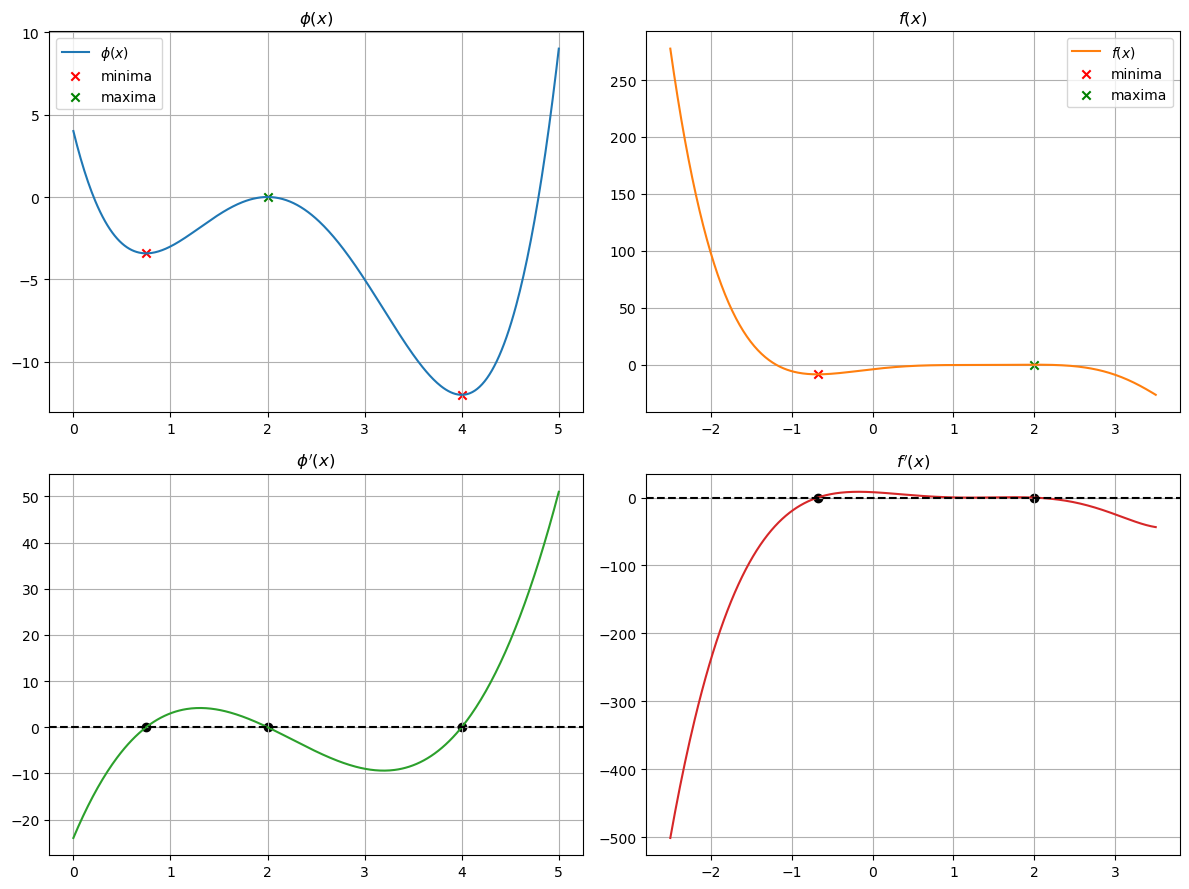

In [9]:
# 2. & 3. 2 by 2 figure plots
x_phi = np.linspace(0, 5, 400)
x_f = np.linspace(-2.5, 3.5, 400)

fig, axs = plt.subplots(2, 2, figsize=(12, 9))

# phi(x) - upper left
axs[0, 0].plot(x_phi, phi(x_phi), label='$\phi(x)$')
axs[0, 0].scatter([phi_min1, phi_min2], [phi(phi_min1), phi(phi_min2)], marker='x', color='red', label='minima')
axs[0, 0].scatter(phi_max, phi(phi_max), marker='x', color='green', label='maxima')
axs[0, 0].set_title('$\phi(x)$')
axs[0, 0].legend()
axs[0, 0].grid(True)

# f(x) - upper right
axs[0, 1].plot(x_f, f(x_f), 'tab:orange', label='$f(x)$')
axs[0, 1].scatter(f_min, f(f_min), marker='x', color='red', label='minima')
axs[0, 1].scatter(f_max, f(f_max), marker='x', color='green', label='maxima')
axs[0, 1].set_title('$f(x)$')
axs[0, 1].legend()
axs[0, 1].grid(True)

# phi'(x) - lower left
axs[1, 0].plot(x_phi, phi_prime(x_phi), 'tab:green')
axs[1, 0].axhline(0, color='black', linestyle='--')
axs[1, 0].scatter([phi_min1, phi_max, phi_min2], [0, 0, 0], color='black')
axs[1, 0].set_title('$\phi\'(x)$')
axs[1, 0].grid(True)

# f'(x) - lower right
axs[1, 1].plot(x_f, f_prime(x_f), 'tab:red')
axs[1, 1].axhline(0, color='black', linestyle='--')
axs[1, 1].scatter([f_min, f_max], [0, 0], color='black')
axs[1, 1].set_title('$f\'(x)$')
axs[1, 1].grid(True)

plt.tight_layout()
plt.show()

#### Problem 1 code summary

Include a brief summary (2–3 sentences) at the bottom of your code outlining the purpose of the script and its core algorithm. Focus on explaining why you wrote the code this way and the reasoning behind your implementation choices.

This script uses the golden-section search to find the local extrema of two equations by narrowing down a bracketed interval. I implemented the core golden-section search algorithm with reference to 5.5.2.2. I made a golden_max function that inverts the equation, allowing it to find maxima using the same logic used to find the minima.